[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/join8112/wafer-yield-portfolio/blob/main/notebooks/04_cnn_colab.ipynb)

# 04 · CNN on wafer maps (train on Colab GPU)

**Goal:** learn defect patterns directly from the map instead of handcrafted features, and check *why* the model decides with Grad-CAM.

**Model:** 3 convolutional blocks → global average pooling → linear (~0.3M parameters). Input has two channels, *is die* and *is failing die*.

**Imbalance:** class-weighted loss (inverse square-root frequency) plus random 90° rotations and flips, which are valid because a defect pattern keeps its meaning when the wafer is rotated.

**Before running on Colab**
1. *Runtime → Change runtime type → T4 GPU*
2. Colab runs on a temporary Google machine that is wiped when the session ends, so the data has to be sent there. Default (`USE_DRIVE = True`): put `wm811k_labeled_64.npz` in Google Drive at `MyDrive/wafer/`; data and results then survive disconnects. Or set `USE_DRIVE = False` to upload the file each session.

In [3]:
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
# True: read data from Google Drive and save results there (survives disconnects).
# False: upload the .npz from your computer each session instead.
USE_DRIVE = True

if IN_COLAB:
    !git clone -q https://github.com/join8112/wafer-yield-portfolio.git
    %cd wafer-yield-portfolio
    !pip install -q -e .
    if USE_DRIVE:
        from google.colab import drive
        drive.mount('/content/drive')
        DATA = Path('/content/drive/MyDrive/wafer/wm811k_labeled_64.npz')
        OUT = '/content/drive/MyDrive/wafer/outputs'
    else:
        from google.colab import files
        DATA = Path('/content/wm811k_labeled_64.npz')
        if not DATA.exists():
            uploaded = files.upload()  # pick data/processed/wm811k_labeled_64.npz
            Path(next(iter(uploaded))).rename(DATA)
        OUT = '/content/outputs'
else:
    DATA = '../data/processed/wm811k_labeled_64.npz'
    OUT = '../reports'

/content/wafer-yield-portfolio/wafer-yield-portfolio/wafer-yield-portfolio
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for wafer (pyproject.toml) ... done
Mounted at /content/drive


In [5]:
import sys
sys.path.insert(0, '/content/wafer-yield-portfolio/src')

In [6]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from wafer import cnn, evaluate
from wafer.data import FAILURE_TYPES
from wafer.eda import WAFER_CMAP
from wafer.preprocess import load_dataset

OUT = Path(OUT); FIG_DIR = OUT / 'figures'; FIG_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')

device: cuda Tesla T4


In [7]:
ds = load_dataset(DATA)
tr, va, te = (ds['split'] == s for s in ('train', 'val', 'test'))
print({s: int(m.sum()) for s, m in zip(('train', 'val', 'test'), (tr, va, te))})

{'train': 121078, 'val': 17287, 'test': 34585}


## 1. Train (~10 minutes on a T4)

In [8]:
%%time
model, history = cnn.train(
    ds['X'][tr], ds['y'][tr], ds['X'][va], ds['y'][va],
    epochs=15, batch_size=256, lr=2e-3, device=DEVICE,
)
torch.save(model.state_dict(), OUT / 'wafer_cnn.pt')

epoch  1  loss 1.1993  val macro-F1 0.4414  (60s)
epoch  2  loss 0.6827  val macro-F1 0.4289  (58s)
epoch  3  loss 0.5178  val macro-F1 0.5445  (61s)
epoch  4  loss 0.4446  val macro-F1 0.7349  (63s)
epoch  5  loss 0.3702  val macro-F1 0.7489  (65s)
epoch  6  loss 0.3342  val macro-F1 0.7895  (66s)
epoch  7  loss 0.3037  val macro-F1 0.8369  (65s)
epoch  8  loss 0.2889  val macro-F1 0.7603  (65s)
epoch  9  loss 0.2699  val macro-F1 0.8062  (65s)
epoch 10  loss 0.2513  val macro-F1 0.8161  (65s)
epoch 11  loss 0.2361  val macro-F1 0.7873  (65s)
epoch 12  loss 0.2245  val macro-F1 0.8331  (65s)
epoch 13  loss 0.2131  val macro-F1 0.8520  (65s)
epoch 14  loss 0.1999  val macro-F1 0.8428  (65s)
epoch 15  loss 0.1934  val macro-F1 0.8481  (65s)
CPU times: user 15min 3s, sys: 27.2 s, total: 15min 31s
Wall time: 16min 7s


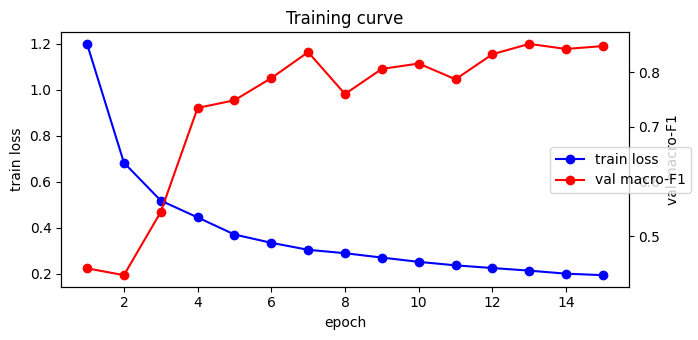

In [9]:
h = pd.DataFrame(history).set_index('epoch')
fig, ax1 = plt.subplots(figsize=(7, 3.5))
ax1.plot(h.index, h['train_loss'], 'b-o', label='train loss')
ax2 = ax1.twinx(); ax2.plot(h.index, h['val_macro_f1'], 'r-o', label='val macro-F1')
ax1.set_xlabel('epoch'); ax1.set_ylabel('train loss'); ax2.set_ylabel('val macro-F1')
fig.legend(loc='center right'); plt.title('Training curve'); plt.tight_layout()
plt.savefig(FIG_DIR / 'cnn_training_curve.png', dpi=150)

## 2. Test-set results

In [10]:
probs = cnn.predict(model, ds['X'][te], device=DEVICE)
pred = probs.argmax(1)
summary = evaluate.summarize(ds['y'][te], pred, ds['n_fail'][te], name='CNN')
summary

,CNN
macro_f1,0.868110
weighted_f1,0.973652
accuracy,0.973486
yield_loss_capture,0.921365


In [11]:
evaluate.per_class_report(ds['y'][te], pred)

,precision,recall,f1-score,support
Center,0.841387,0.932480,0.884594,859.0
Donut,0.774194,0.864865,0.817021,111.0
Edge-Loc,0.811927,0.852601,0.831767,1038.0
Edge-Ring,0.985005,0.983988,0.984496,1936.0
Loc,0.787781,0.681502,0.730798,719.0
Near-full,0.906250,0.966667,0.935484,30.0
Random,0.917160,0.895954,0.906433,173.0
Scratch,0.654605,0.832636,0.732965,239.0
none,0.991484,0.987381,0.989429,29480.0


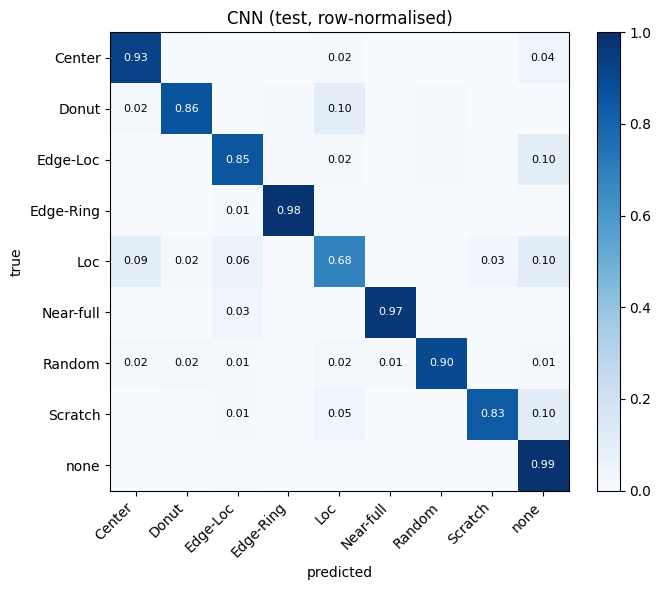

In [12]:
fig = evaluate.plot_confusion(ds['y'][te], pred, 'CNN (test, row-normalised)')
fig.savefig(FIG_DIR / 'cnn_confusion.png', dpi=150)

## 3. Grad-CAM: what is the model looking at?

For each class, one correctly classified test wafer. Red dies are failures; the heat-map overlay shows the regions that drove the prediction.

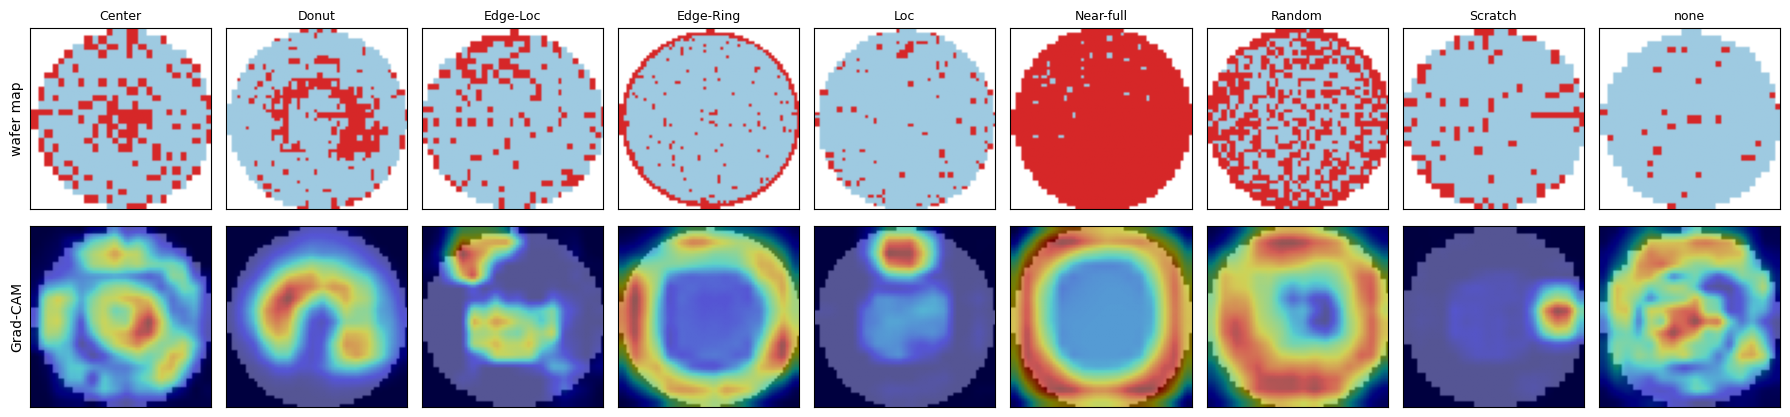

In [13]:
test_idx = np.flatnonzero(te)
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, len(FAILURE_TYPES), figsize=(2 * len(FAILURE_TYPES), 4.4))
for k, name in enumerate(FAILURE_TYPES):
    hits = test_idx[(ds['y'][te] == k) & (pred == k)]
    for ax in axes[:, k]: ax.set_xticks([]); ax.set_yticks([])
    axes[0, k].set_title(name, fontsize=9)
    if len(hits) == 0: continue
    i = rng.choice(hits)
    cam, _ = cnn.grad_cam(model, ds['X'][i], target=k)
    axes[0, k].imshow(ds['X'][i], cmap=WAFER_CMAP, vmin=0, vmax=2)
    axes[1, k].imshow(ds['X'][i] > 0, cmap='gray', vmin=0, vmax=1.5)
    axes[1, k].imshow(cam, cmap='jet', alpha=0.5)
axes[0, 0].set_ylabel('wafer map'); axes[1, 0].set_ylabel('Grad-CAM')
plt.tight_layout(); plt.savefig(FIG_DIR / 'cnn_gradcam.png', dpi=150)

## 4. Save results and copy them into the repo

In [14]:
report = evaluate.per_class_report(ds['y'][te], pred)
results = {
    'model': 'CNN (3 conv blocks, 2-channel 64x64 input)',
    **summary.round(4).to_dict(),
    'recall_per_class': report['recall'].round(4).to_dict(),
    'epochs': len(history),
}
(OUT / 'results_cnn.json').write_text(json.dumps(results, indent=2))
results

{'model': 'CNN (3 conv blocks, 2-channel 64x64 input)',
 'macro_f1': 0.8681,
 'weighted_f1': 0.9737,
 'accuracy': 0.9735,
 'yield_loss_capture': 0.9214,
 'recall_per_class': {'Center': 0.9325,
  'Donut': 0.8649,
  'Edge-Loc': 0.8526,
  'Edge-Ring': 0.984,
  'Loc': 0.6815,
  'Near-full': 0.9667,
  'Random': 0.896,
  'Scratch': 0.8326,
  'none': 0.9874},
 'epochs': 15}

In [15]:
if IN_COLAB:
    # Downloads results_cnn.json, the figures and the model weights as one zip.
    import shutil
    from google.colab import files
    shutil.make_archive('/content/cnn_outputs', 'zip', OUT)
    files.download('/content/cnn_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Unzip `cnn_outputs.zip` into the repo's `reports/` folder (`results_cnn.json` → `reports/`, PNGs → `reports/figures/`). Then *File → Download → Download .ipynb* and replace `notebooks/04_cnn_colab.ipynb`, so the outputs show on GitHub.

## Findings

**Headline: the CNN edges out the feature baseline overall, and the two models make different mistakes.**

| Metric (test, 34,585 wafers) | LightGBM baseline | CNN | Change |
|---|---|---|---|
| Macro-F1 | 0.861 | **0.868** | +0.007 |
| Yield-loss capture | 0.921 | 0.921 | ≈ 0 |
| Accuracy | 0.967 | 0.973 | +0.006 |

| Recall by class | LightGBM | CNN |
|---|---|---|
| Scratch | 0.70 | **0.83** |
| Center | 0.90 | **0.93** |
| Donut | 0.82 | **0.86** |
| Random | 0.87 | **0.90** |
| Edge-Ring | 0.98 | 0.98 |
| Edge-Loc | **0.87** | 0.85 |
| Near-full | **1.00** | 0.97 (1 of 30 missed) |
| Loc | **0.76** | 0.68 |

**What the CNN fixed:** `Scratch` recall rose from 0.70 to 0.83. A scratch is a thin line, which ring averages and cluster statistics describe poorly but convolutions pick up directly. This was the baseline's biggest weakness.

**What got worse:** `Loc` recall fell from 0.76 to 0.68. The CNN now confuses `Loc` with `Center` (9%) and `Edge-Loc` (6%): a local cluster's *position* decides between these three classes, and the handcrafted "distance of the largest cluster from the centre" feature encodes position more explicitly than a CNN with global average pooling.

**How confident is the +0.007?** Not very. This is a single training run with one random seed, and validation macro-F1 still moved between 0.76 and 0.85 from epoch to epoch. The honest reading is that **the two models are roughly on par overall but complementary**: the CNN is better on shape (Scratch), the features are better on position (Loc). That makes an ensemble the natural next step.

**Grad-CAM sanity check:** the model looks at the right dies. Heat sits on the wafer edge for `Edge-Ring`, on the line for `Scratch`, on the local blob for `Loc`, and on the ring for `Donut`. This matters for a fab: a model that scored well by keying on artefacts (map size, die count) would not transfer to new products.

**Training:** 15 epochs, 16 minutes on a free Colab T4. Validation macro-F1 was still noisy and rising at the end, so more epochs, a lower learning rate or averaging several seeds would likely help.

**Next steps for this model**
1. Average the CNN's and LightGBM's predicted probabilities (cheap, uses existing models).
2. Add the wafer's polar coordinates as extra input channels, so the CNN can use position the way the features do.
3. Report the mean and spread over 3–5 seeds instead of a single run.
